[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Nearest Neighbors


## What you will be able to do

Two of the named stations sit just outside Norway's simplified coastline, so no shape contains them.
With `sjoin_nearest` you match each row to the closest shape instead, keep the distance, and set how
far a match may reach.

## The idea

### The problem

Every station in the register reports to one of the five named stations, the one closest to it. The forecasters want that pairing for all 300
stations, with the distance, so they can see which named station carries the most and which station
lies farthest from any of them.

The **Why GeoPandas** notebook also left two named stations without a country. Tromso and Kirkenes
stand on the water's edge, and the 1:50m outline puts the coast slightly inland of them, so a join
on `within` finds no country for either. A join that asks for the closest shape, and says how far
away it is, places both and shows how far each one is from the outline.

### A formal definition

> A **nearest join** matches each row of the left table with the row of the right table whose
> geometry is closest to it. In GeoPandas, `gpd.sjoin_nearest(left, right, distance_col=...,
> max_distance=...)` adds the matching right row's columns and `index_right`, and, when given
> `distance_col`, a column holding the distance between the two geometries, in the units of the CRS.
> Rows farther than `max_distance` from every right geometry find no match.

### Why it works that way

Distance is measured in the units of the CRS, so the CRS decides what "closest" means. In UTM zone
33N the units are meters, the same in every direction. In degrees, a step of one degree of longitude
is about half as long at 60 degrees north as a step of one degree of latitude, and shorter still in
the far north. A search in degrees counts every east and west step at the length of a north and south
one, so the nearest station it finds can be the wrong one. GeoPandas warns when asked to measure in degrees.

The join uses the right table's spatial index to find the closest shapes quickly. When two shapes are
equally close, the left row appears once for each, so a tie adds rows. `max_distance` limits the
search, and a row with nothing inside that limit drops out of an inner join or keeps `NaN` in a left
join. A distance to a polygon is measured to its edge, and a point inside the polygon is at distance
0.

### Where this shows up

Assigning customers to the nearest store, sensors to the nearest road, or a point that misses every
polygon to the one it was meant for. The **Spatial Joins** notebook joined on containment, and the
**A Station Atlas** notebook pairs every station with its nearest named station.

### What this notebook covers

- the nearest named station for every station, with the distance
- placing Tromso and Kirkenes, and how far they are from the outline
- limiting a match with `max_distance`
- ties
- each station's nearest neighbor in its own table
- four mistakes made with nearest joins

### A first look

Before any of the detail, here is the whole idea in a few lines. There is nothing to run yet: read it,
and read the output underneath it. Everything from Setup onward is where you start running things.

```python
import geopandas as gpd
from shapely.geometry import Point

towns = gpd.GeoDataFrame({"town": ["Ash", "Birch"]}, geometry=[Point(0, 0), Point(10, 0)])
sites = gpd.GeoDataFrame({"site": [1, 2, 3]}, geometry=[Point(2, 1), Point(7, 0), Point(30, 0)])
near = gpd.sjoin_nearest(sites, towns, distance_col="distance", max_distance=10, how="left")
print(near[["site", "town", "distance"]].round(2))
```

```
   site   town  distance
0     1    Ash      2.24
1     2  Birch      3.00
2     3    NaN       NaN
```

Each site gets the town closest to it and the distance. The third site is 20 units from Birch, beyond
the limit of 10, so the left join keeps it with no town.

## Setup

Two libraries for the tables, GeoPandas and Shapely for the geometry, Matplotlib for the map, and the
standard library's `warnings`.

- `Path` finds the guide's copy of the country outlines, when the notebook runs beside it
- `warnings` catches the warning a nearest join gives in degrees
- `numpy` and `pandas` build the made-up register
- `geopandas` reads the outlines and does every join, and the cell prints its version
- `shapely` builds the districts, and draws the lines from each station to its match
- `matplotlib.pyplot` draws the map

`countries` holds the outlines of Denmark, Finland, Norway, Russia and Sweden, clipped to the Nordic
area, in degrees. Made with Natural Earth. The outlines come from Natural Earth's 1:50m map of the
world's countries, which is in the public domain.

`stations` is the register of 300 stations as a GeoDataFrame in degrees, and `named` holds the five
named stations at their real positions. `districts` holds the eight forecast districts in UTM zone
33N, in meters. The stations and the districts are made up. The stations are drawn at random over
mainland Norway from a fixed seed, and the districts are drawn around eight chosen centers and cut to
Norway's outline.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
stations = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
)

named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)

districts = forecast_districts()
print("geopandas", gpd.__version__, "|", len(stations), "made-up stations,", len(named), "named stations,",
      len(districts), "made-up districts")

geopandas 1.2.0 | 300 made-up stations, 5 named stations, 8 made-up districts


## Worked examples

### The nearest named station for every station

Both tables go to UTM zone 33N first, so that distances are in meters.

In [2]:
stations_m = stations.to_crs(25833)
named_m = named.to_crs(25833)
nearest = gpd.sjoin_nearest(stations_m, named_m[["name", "geometry"]], distance_col="distance_m")
nearest["km"] = (nearest["distance_m"] / 1000).round(1)
print(len(nearest), "rows")
nearest[["station", "name", "km"]].head()

300 rows


,station,name,km
0,NS001,Oslo,141.6
1,NS002,Oslo,564.8
2,NS003,Kirkenes,238.1
3,NS004,Tromso,65.7
4,NS005,Oslo,293.3


Each of the 300 stations has one named station and the distance to it. The first station, NS001, is
141.6 km from Oslo.

In [3]:
load = nearest.groupby("name")["km"].agg(["mean", "max"]).reindex(named["name"])
load.insert(0, "stations", nearest.groupby("name").size().reindex(named["name"], fill_value=0))
load.round(1)

,stations,mean,max
name,,,
Bergen,67,171.8,394.9
Oslo,129,250.9,574.4
Svalbard,0,NaN,NaN
Tromso,74,249.9,577.2
Kirkenes,30,143.2,238.1


Oslo carries the most stations, 129, and the farthest of them is 574.4 km away. Svalbard carries none,
since every station in the register is on the mainland. A `groupby` of the joined table has no group
for a name that never matched, so `reindex` gives Svalbard's mean and maximum `NaN`, and its count,
reindexed with `fill_value=0`, is 0.

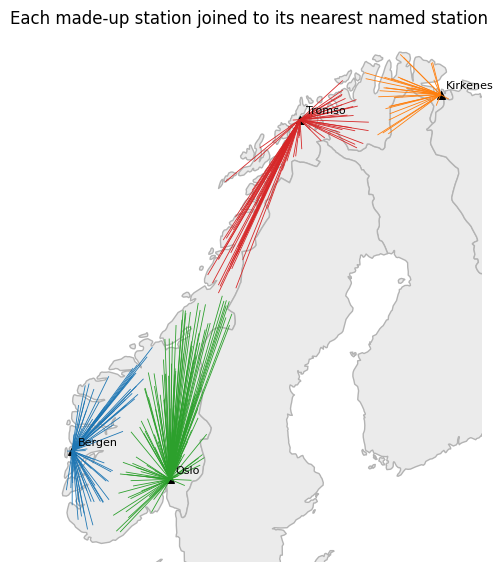

In [4]:
lines = nearest.assign(geometry=shapely.shortest_line(
    nearest.geometry.to_numpy(), named_m.geometry.loc[nearest["index_right"]].to_numpy()))
fig, ax = plt.subplots(figsize=(6, 7))
countries.to_crs(25833).plot(ax=ax, color="0.92", edgecolor="0.7")
lines.plot(ax=ax, column="name", categorical=True, linewidth=0.6)
named_m.plot(ax=ax, color="black", marker="^", markersize=30)
for name, point in zip(named_m["name"], named_m.geometry):
    ax.annotate(name, (point.x, point.y), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.set_axis_off()
ax.set_title("Each made-up station joined to its nearest named station")
plt.show()

`shortest_line` draws a line from each station to the named station it was matched with, so every
station's line runs to the closest triangle, and each named station's lines have a color of their own. The lines from the middle of the country run south to Oslo
and north to Tromso, and they meet where the two are equally far away.

### Placing Tromso and Kirkenes

A distance to a polygon is measured to its edge, and a point inside the polygon is at 0.

In [5]:
countries_m = countries.to_crs(25833)
placed = gpd.sjoin_nearest(named_m, countries_m[["ADMIN", "geometry"]], distance_col="distance_m")
placed[["name", "ADMIN", "distance_m"]].round(0)

,name,ADMIN,distance_m
0,Bergen,Norway,0.0
1,Oslo,Norway,0.0
2,Svalbard,Norway,0.0
3,Tromso,Norway,2659.0
4,Kirkenes,Norway,481.0


Bergen, Oslo and Svalbard are inside Norway's outline. Tromso is 2,659 meters outside it and Kirkenes
481 meters, which is how far the 1:50m coast was drawn from where these two towns stand. The nearest
country for both is Norway.

The same join gives each named station a district.

In [6]:
gpd.sjoin_nearest(named_m, districts, distance_col="distance_m")[["name", "district", "distance_m"]].round(0)

,name,district,distance_m
0,Bergen,West,0.0
1,Oslo,East,0.0
2,Svalbard,Svalbard,0.0
3,Tromso,Far North,2659.0
4,Kirkenes,Northeast,481.0


Tromso falls in Far North and Kirkenes in Northeast, at the same distances, since the districts were
cut from the same outline.

### Limiting a match with max_distance

`max_distance` is in the units of the CRS. With a left join, a row with nothing inside the limit keeps
`NaN`.

In [7]:
for limit in [5_000, 500]:
    limited = gpd.sjoin_nearest(named_m, countries_m[["ADMIN", "geometry"]], how="left",
                               max_distance=limit, distance_col="distance_m")
    print(f"max_distance={limit}:", limited["ADMIN"].tolist())

max_distance=5000: ['Norway', 'Norway', 'Norway', 'Norway', 'Norway']
max_distance=500: ['Norway', 'Norway', 'Norway', nan, 'Norway']


A limit of 5 km places both towns. A limit of 500 meters still places Kirkenes, 481 meters out, and
leaves Tromso without a country. A limit is a statement of how far off a point may be and still
belong to a shape, and it keeps a point that is far from everything from being matched anyway.

In [8]:
close = gpd.sjoin_nearest(stations_m, named_m[["name", "geometry"]], max_distance=100_000)
print("stations within 100 km of a named station:", len(close), "of", len(stations_m))
close.groupby("name").size().reindex(named["name"], fill_value=0)

stations within 100 km of a named station: 52 of 300


name
Bergen      13
Oslo        20
Svalbard     0
Tromso      12
Kirkenes     7
dtype: int64

The default inner join keeps only the 52 stations within 100 km of a named station. The other 248 are
farther than that from all five.

### Ties

A point exactly halfway between two named stations is equally close to both.

In [9]:
bergen, oslo = named_m.geometry.iloc[0], named_m.geometry.iloc[1]
halfway = gpd.GeoDataFrame({"point": ["halfway"]},
                           geometry=[shapely.Point((bergen.x + oslo.x) / 2, (bergen.y + oslo.y) / 2)],
                           crs=25833)
tie = gpd.sjoin_nearest(halfway, named_m[["name", "geometry"]], distance_col="distance_m")
tie.assign(km=(tie["distance_m"] / 1000).round(1))[["point", "name", "km"]].sort_values("name")

,point,name,km
0,halfway,Bergen,153.3
0,halfway,Oslo,153.3


The one point comes back as two rows, one for Bergen and one for Oslo, each 153.3 km away. A count
of rows after a nearest join counts a tied point twice, so check `index` for repeats when the answer
must be one row per point.

### Each station's nearest neighbor in its own table

Joining a table to itself pairs every station with another station. `exclusive=True` leaves out the
match of a geometry with an identical one, which here is the station itself.

In [10]:
neighbors = gpd.sjoin_nearest(stations_m[["station", "geometry"]], stations_m[["station", "geometry"]],
                              distance_col="distance_m", exclusive=True)
print(neighbors[["station_left", "station_right"]].head(3).to_string(index=False))
(neighbors["distance_m"] / 1000).describe().round(1)

station_left station_right
       NS001         NS215
       NS002         NS041
       NS003         NS018


count    300.0
mean      17.7
std       10.1
min        1.7
25%       10.8
50%       16.2
75%       22.9
max       85.1
Name: distance_m, dtype: float64

The two `station` columns get the suffixes `_left` and `_right`. Half of the stations have a neighbor
within 16.2 km, and the most isolated station is 85.1 km from any other.

## Your turn

Five tasks. Write your answer in the cell under each task and run it.

Try a task before you look at its answer. Reading a solution teaches you much less than
getting there yourself, even slowly.

When you are ready: [**open the solutions notebook**](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/09-nearest-neighbors-solutions.ipynb).

**1.** Find the station farthest from its nearest named station, and print its id, the named station and the distance in kilometers.

In [11]:
# your code here

**2.** Give each named station its nearest country other than Norway, and print the country and the distance in kilometers.

In [12]:
# your code here

**3.** Count how many stations have a named station within 200 km, with a left join and `max_distance`, and print how many have none.

In [13]:
# your code here

**4.** Pair every station in the Mid district with its nearest station outside Mid, and print the five shortest pairs with their distances in kilometers.

In [14]:
# your code here

**5.** For the `airport` stations only, find each one's nearest `airport` station, and print the mean of those distances in kilometers.

In [15]:
# your code here

## Common errors

### `UserWarning: Geometry is in a geographic CRS. Results from 'sjoin_nearest' are likely incorrect.`

The stations and the named stations are joined in degrees.

In [16]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", UserWarning)
    in_degrees = gpd.sjoin_nearest(stations, named[["name", "geometry"]])
messages = [f"{w.category.__name__}: {str(w.message).splitlines()[0]}" for w in caught]
for message in dict.fromkeys(messages):
    print(message, f"(shown {messages.count(message)} times)")

The message goes on to say that the geometries should go to a projected CRS with `to_crs`. It comes
twice here, as the count shows. The join still runs, and the next error shows what its
answer is worth.

### No error, and 21 stations matched to a different named station

In [17]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    by_degrees = gpd.sjoin_nearest(stations, named[["name", "geometry"]])
by_meters = gpd.sjoin_nearest(stations.to_crs(25833), named.to_crs(25833)[["name", "geometry"]])
changed = by_degrees["name"] != by_meters["name"]
print("stations matched differently:", changed.sum())
pd.crosstab(by_degrees.loc[changed, "name"], by_meters.loc[changed, "name"],
            rownames=["in degrees"], colnames=["in meters"])

stations matched differently: 21


in meters,Bergen,Kirkenes,Oslo,Tromso
in degrees,,,,
Bergen,0,0,1,0
Oslo,9,0,0,9
Tromso,0,2,0,0


The cell silences the warning the previous error showed, as code that ignores it would. In degrees,
21 of the 300 stations get the wrong named station: nine that are closer to Bergen and nine that are
closer to Tromso go to Oslo, two that are closer to Kirkenes go to Tromso, and one closer to Oslo goes
to Bergen. A degree of longitude is about half as long on the ground as a degree of latitude here, and
a search in degrees counts the two as equal, so it ranks some distances in the wrong order. Convert
both tables to a CRS in meters before the join.

### No error, and Tromso and Kirkenes without a country

In [18]:
named_m = named.to_crs(25833)
countries_m = countries.to_crs(25833)
gpd.sjoin_nearest(named_m, countries_m[["ADMIN", "geometry"]], how="left", max_distance=5)[["name", "ADMIN"]]

,name,ADMIN
0,Bergen,Norway
1,Oslo,Norway
2,Svalbard,Norway
3,Tromso,NaN
4,Kirkenes,NaN


The limit was meant as 5 km, and `max_distance` is in the units of the CRS, so it is 5 meters here,
and the two towns 2,659 and 481 meters from the outline find no country. Write the limit in the CRS's
units, `max_distance=5_000`.

### No error, and every station's nearest neighbor is itself

In [19]:
stations_m = stations.to_crs(25833)
itself = gpd.sjoin_nearest(stations_m[["station", "geometry"]], stations_m[["station", "geometry"]],
                           distance_col="distance_m")
print("matched to itself:", (itself["station_left"] == itself["station_right"]).sum())
print("largest distance:", itself["distance_m"].max())

matched to itself: 300
largest distance: 0.0


In a table joined to itself, the closest geometry to each station is its own point, at distance 0, so
all 300 stations are matched to themselves. Pass `exclusive=True`, as the worked examples did, to
leave out a geometry's match with an identical one.

## Recap

- You can match every row to the closest shape in another table with `sjoin_nearest`, in a CRS
  measured in meters.
- You can keep the distance with `distance_col`, and read it in the CRS's units.
- You can limit a match with `max_distance`, and choose a left join to keep the rows that find
  nothing.
- You can recognize a tie by a repeated index.
- You can find each point's nearest neighbor in its own table with `exclusive=True`.

## What is next

The **Buffers, Overlays and Clipping** notebook draws zones of a chosen distance around shapes, and
cuts two layers into the pieces they make together.

---

&#8592; **Previous:** [Spatial Joins](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/08-spatial-joins.ipynb)  &nbsp;·&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)  &nbsp;·&nbsp;  **Next:** [Buffers, Overlays and Clipping](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/10-buffers-overlays-and-clipping.ipynb) &#8594;
